# Desempeño frente a costo: la frontera de Pareto

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 12, unidad 5 · Genera la figura de la lámina «La frontera de Pareto»

---

Once semanas comparando métodos por su riesgo esperado, sin preguntar nunca
cuánto cuesta obtenerlo. Este cuaderno pone el costo en el otro platillo.

Se ajustan siete configuraciones —desde una regresión logística hasta una red
multicapa— y se mide, para cada una:

| Eje | Qué se mide |
|---|---|
| **Desempeño** | AUC-ROC sobre el conjunto de prueba, con su variabilidad |
| **Costo de entrenamiento** | Segundos de ajuste, con el presupuesto declarado |
| **Costo de inferencia** | Milisegundos por 1 000 casos —el que domina en producción |

Y se construye la **frontera de Pareto**: el conjunto de métodos que **ningún
otro domina** en ambos ejes a la vez.

## Por qué una frontera y no un ganador

Preguntar «cuál es el mejor» está mal planteado en cuanto hay dos criterios. La
frontera reformula la pregunta: hay un conjunto de opciones no dominadas, y
elegir entre ellas depende de las restricciones del problema —no del método.

## 1. Entorno

In [1]:
import sys, platform, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              ExtraTreesClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

print("Python       ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy        ", np.__version__)
print("scikit-learn ", sklearn.__version__)
print("plataforma   ", platform.processor() or platform.machine())

Python        3.12.14 | Darwin arm64
numpy         2.2.6
scikit-learn  1.9.0
plataforma    arm


In [2]:
SEMILLA = 22
N_CASOS = 8000
N_ATRIBUTOS = 25
N_REPLICAS = 5
N_INFERENCIA = 1000      # casos por medición de tiempo de inferencia

print(f"Casos: {N_CASOS:,}  |  atributos: {N_ATRIBUTOS}  |  réplicas: {N_REPLICAS}")

Casos: 8,000  |  atributos: 25  |  réplicas: 5


## 2. Las configuraciones

Siete, ordenadas de menor a mayor capacidad. Se incluyen deliberadamente
**variantes del mismo método con distinto tamaño** —bosques de 50 y de 500
árboles— para que la frontera muestre el costo marginal de cada mejora.

La primera es la **línea base simple** que el taller 6 exige siempre.

In [3]:
configuraciones = {
    "Logística":            lambda s: make_pipeline(StandardScaler(),
                                LogisticRegression(max_iter=2000, random_state=s)),
    "k-NN (k=15)":          lambda s: make_pipeline(StandardScaler(),
                                KNeighborsClassifier(n_neighbors=15)),
    "Bosque, 50":           lambda s: RandomForestClassifier(n_estimators=50,
                                random_state=s, n_jobs=1),
    "Bosque, 500":          lambda s: RandomForestClassifier(n_estimators=500,
                                random_state=s, n_jobs=1),
    "Árboles extra, 500":   lambda s: ExtraTreesClassifier(n_estimators=500,
                                random_state=s, n_jobs=1),
    "Potenciación":         lambda s: HistGradientBoostingClassifier(
                                max_iter=300, random_state=s),
    "Red (128, 64)":        lambda s: make_pipeline(StandardScaler(),
                                MLPClassifier(hidden_layer_sizes=(128, 64),
                                              max_iter=400, early_stopping=True,
                                              random_state=s)),
}
print(f"Configuraciones a comparar: {len(configuraciones)}")

Configuraciones a comparar: 7


**Sobre `n_jobs=1`**: se fuerza un solo hilo en los ensambles para que el
tiempo medido sea comparable entre métodos. Con paralelismo, el tiempo depende
de cuántos núcleos haya libres en ese momento, y la comparación deja de ser
reproducible —que es el ítem 1 de la lista de cotejo.

## 3. La medición

In [4]:
def mide(construye, X_ent, y_ent, X_pru, y_pru, semilla):
    modelo = construye(semilla)

    t0 = time.perf_counter()
    modelo.fit(X_ent, y_ent)
    t_entrenamiento = time.perf_counter() - t0

    p = modelo.predict_proba(X_pru)[:, 1]
    auc = roc_auc_score(y_pru, p)

    # Inferencia: se promedia sobre varias pasadas para reducir el ruido de medición.
    lote = X_pru[:N_INFERENCIA]
    modelo.predict_proba(lote)                      # descarta la primera, que calienta
    t0 = time.perf_counter()
    for _ in range(3):
        modelo.predict_proba(lote)
    t_inferencia = (time.perf_counter() - t0) / 3 * 1000   # ms por 1000 casos

    return auc, t_entrenamiento, t_inferencia


rng = np.random.default_rng(SEMILLA)
resultados = {k: {"auc": [], "t_ent": [], "t_inf": []} for k in configuraciones}

for k in range(N_REPLICAS):
    X, y = make_classification(n_samples=N_CASOS, n_features=N_ATRIBUTOS,
                               n_informative=12, n_redundant=5, class_sep=0.9,
                               random_state=int(rng.integers(0, 10**6)))
    X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.3,
                                                  stratify=y, random_state=k)
    for nombre, construye in configuraciones.items():
        auc, te, ti = mide(construye, X_ent, y_ent, X_pru, y_pru, semilla=k)
        resultados[nombre]["auc"].append(auc)
        resultados[nombre]["t_ent"].append(te)
        resultados[nombre]["t_inf"].append(ti)

for nombre in resultados:
    for clave in resultados[nombre]:
        resultados[nombre][clave] = np.array(resultados[nombre][clave])
print("mediciones completadas")

mediciones completadas


In [5]:
print(f"{'configuración':>20} {'AUC':>16} {'entren. (s)':>13} {'inf. (ms/1000)':>16}")
print("-" * 70)
orden = sorted(resultados, key=lambda k: -resultados[k]["auc"].mean())
for nombre in orden:
    r = resultados[nombre]
    print(f"{nombre:>20} {r['auc'].mean():>9.4f} ± {r['auc'].std():.4f} "
          f"{r['t_ent'].mean():>13.2f} {r['t_inf'].mean():>16.1f}")

       configuración              AUC   entren. (s)   inf. (ms/1000)
----------------------------------------------------------------------
       Red (128, 64)    0.9870 ± 0.0018          0.75              0.6
        Potenciación    0.9869 ± 0.0022          5.27             32.6
  Árboles extra, 500    0.9841 ± 0.0043          2.13             74.6
         Bosque, 500    0.9793 ± 0.0058          5.88             54.3
         k-NN (k=15)    0.9782 ± 0.0039          0.00             15.7
          Bosque, 50    0.9755 ± 0.0066          0.61              5.5
           Logística    0.8744 ± 0.0512          0.01              0.2


## 4. La frontera de Pareto

Una configuración $A$ **domina** a $B$ si $A$ no es peor en ningún eje y es mejor
en al menos uno. Las no dominadas forman la frontera.

In [6]:
def frontera(puntos):
    """puntos: {nombre: (costo, desempeño)}. Devuelve los no dominados."""
    no_dominados = []
    for a, (ca, da) in puntos.items():
        dominado = any((cb <= ca and db >= da) and (cb < ca or db > da)
                       for b, (cb, db) in puntos.items() if b != a)
        if not dominado:
            no_dominados.append(a)
    return no_dominados

puntos_ent = {k: (resultados[k]["t_ent"].mean(), resultados[k]["auc"].mean())
              for k in resultados}
puntos_inf = {k: (resultados[k]["t_inf"].mean(), resultados[k]["auc"].mean())
              for k in resultados}

f_ent = frontera(puntos_ent)
f_inf = frontera(puntos_inf)

print("Frontera de Pareto, desempeño frente a COSTO DE ENTRENAMIENTO:")
for k in sorted(f_ent, key=lambda k: puntos_ent[k][0]):
    print(f"   {k:<20} {puntos_ent[k][0]:>7.2f} s   AUC {puntos_ent[k][1]:.4f}")
print()
print("Frontera de Pareto, desempeño frente a COSTO DE INFERENCIA:")
for k in sorted(f_inf, key=lambda k: puntos_inf[k][0]):
    print(f"   {k:<20} {puntos_inf[k][0]:>7.1f} ms   AUC {puntos_inf[k][1]:.4f}")
print()
dominadas = [k for k in resultados if k not in f_ent and k not in f_inf]
print(f"Dominadas en ambos ejes: {dominadas if dominadas else '(ninguna)'}")

Frontera de Pareto, desempeño frente a COSTO DE ENTRENAMIENTO:
   k-NN (k=15)             0.00 s   AUC 0.9782
   Red (128, 64)           0.75 s   AUC 0.9870

Frontera de Pareto, desempeño frente a COSTO DE INFERENCIA:
   Logística                0.2 ms   AUC 0.8744
   Red (128, 64)            0.6 ms   AUC 0.9870

Dominadas en ambos ejes: ['Bosque, 50', 'Bosque, 500', 'Árboles extra, 500', 'Potenciación']


## 5. El costo marginal

La frontera responde a la pregunta que interesa: **cuánto cuesta cada décima
adicional de desempeño**.

In [7]:
mejor = max(resultados, key=lambda k: resultados[k]["auc"].mean())
base = "Logística"

d_auc = resultados[mejor]["auc"].mean() - resultados[base]["auc"].mean()
r_ent = resultados[mejor]["t_ent"].mean() / resultados[base]["t_ent"].mean()
r_inf = resultados[mejor]["t_inf"].mean() / resultados[base]["t_inf"].mean()

print(f"Mejor configuración: {mejor}")
print(f"Línea base:          {base}")
print()
print(f"Ganancia de AUC:                {d_auc:+.4f}")
print(f"Costo de entrenamiento:         {r_ent:.1f}x")
print(f"Costo de inferencia:            {r_inf:.1f}x")
print()
print("Y la pregunta que ninguna métrica responde:")
print(f"  ¿cambia una ganancia de {d_auc:.4f} en AUC alguna decisión en su problema?")

Mejor configuración: Red (128, 64)
Línea base:          Logística

Ganancia de AUC:                +0.1126
Costo de entrenamiento:         80.4x
Costo de inferencia:            2.8x

Y la pregunta que ninguna métrica responde:
  ¿cambia una ganancia de 0.1126 en AUC alguna decisión en su problema?


## 6. Figura

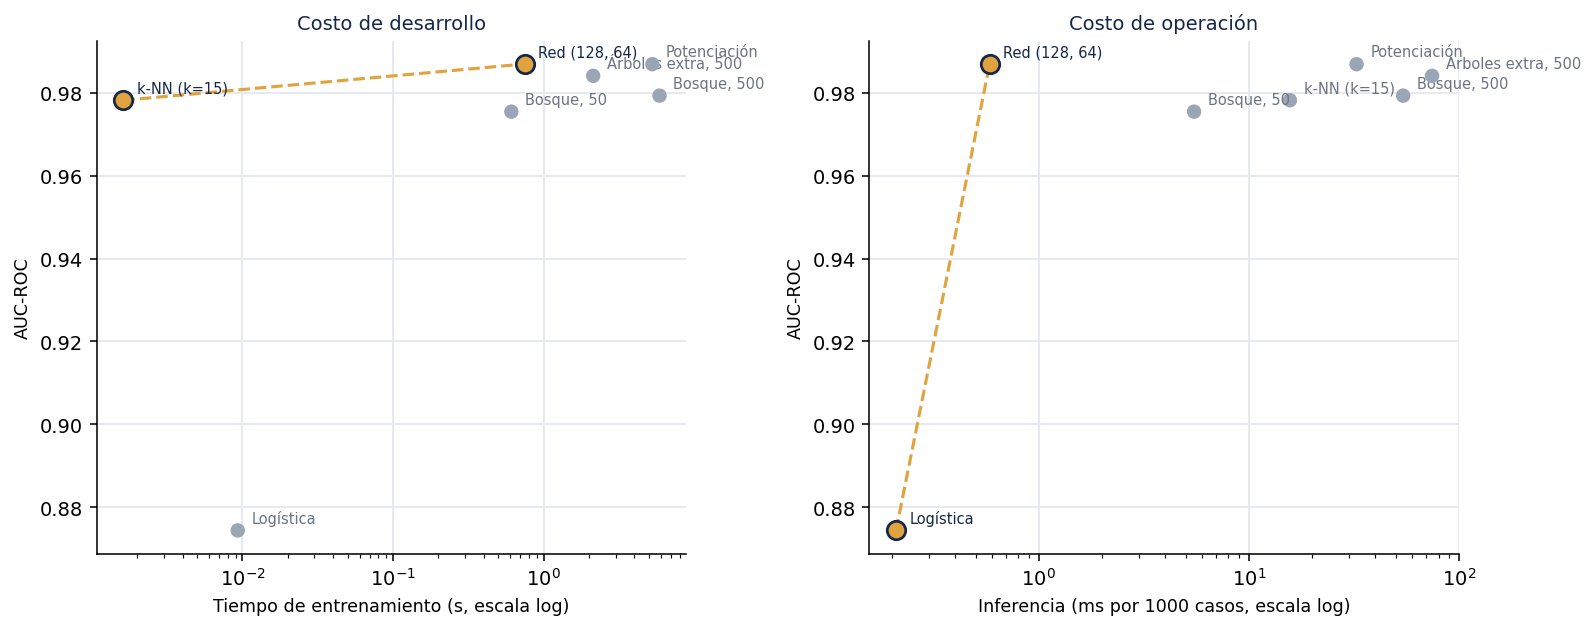

In [8]:
#| label: fig-pareto
#| fig-cap: "Desempeño frente a costo de entrenamiento y de inferencia, con la frontera de Pareto."
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.6), dpi=140)

for ax, puntos, front, xlabel, titulo in [
        (a1, puntos_ent, f_ent, "Tiempo de entrenamiento (s, escala log)",
         "Costo de desarrollo"),
        (a2, puntos_inf, f_inf, "Inferencia (ms por 1000 casos, escala log)",
         "Costo de operación")]:
    for nombre, (c, d) in puntos.items():
        en_frontera = nombre in front
        ax.scatter(c, d, s=90 if en_frontera else 55,
                   color="#E0A33E" if en_frontera else "#9AA5B5",
                   edgecolors="#16264A" if en_frontera else "none",
                   linewidths=1.4, zorder=4 if en_frontera else 3)
        ax.annotate(nombre, (c, d), textcoords="offset points", xytext=(7, 4),
                    fontsize=7.5, color="#16264A" if en_frontera else "#6B7480")
    ordenados = sorted(front, key=lambda k: puntos[k][0])
    ax.plot([puntos[k][0] for k in ordenados], [puntos[k][1] for k in ordenados],
            lw=1.6, ls="--", color="#E0A33E", zorder=2)
    ax.set_xscale("log")
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_ylabel("AUC-ROC", fontsize=9)
    ax.set_title(titulo, fontsize=10, color="#16264A")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#E6EAF0", lw=1); ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("frontera_de_pareto.png", dpi=200, bbox_inches="tight")
plt.show()

Los puntos ámbar son la frontera; los grises están **dominados** —hay otra
configuración igual de buena y más barata, así que no hay razón para elegirlos.

Las dos fronteras **no coinciden**, y eso es lo importante: un método puede ser
barato de entrenar y caro de operar, o al revés. Si su sistema va a predecir
durante cinco años, la figura de la derecha es la que decide.

## 7. Una advertencia sobre estas mediciones

El tiempo medido **no es una propiedad del algoritmo**: depende del hardware, de
la implementación, de la carga de la máquina y de la versión de la biblioteca.

::: Por eso :::

- Se fija `n_jobs=1` para que el paralelismo no contamine la comparación.
- Se promedia sobre varias pasadas y se descarta la primera.
- Se declara el hardware en la sección 1.
- Y **no se comparan estos números con los de otra máquina**.

Lo que sí es transferible son las **razones** entre métodos, y la forma de la
frontera. El taller 6 pide exactamente eso, no valores absolutos.

## 8. Bitácora

**Decisiones tomadas**

1. *Siete configuraciones, incluidas variantes del mismo método.* Bosques de 50 y
   500 árboles hacen visible el **costo marginal**: cuánto AUC compra multiplicar
   por diez el cómputo. Con un método por familia, la frontera tendría pocos
   puntos y no mostraría eso.
2. *`n_jobs=1` en los ensambles.* Con paralelismo el tiempo depende de los núcleos
   libres en ese instante y la medición deja de ser reproducible. Se pierde
   realismo y se gana comparabilidad; en producción habría que medir con el
   paralelismo real.
3. *Inferencia sobre 1 000 casos, promediada en tres pasadas, descartando la
   primera.* La primera llamada incluye asignación de memoria y cachés fríos.
4. *Dos fronteras y no una.* Entrenamiento e inferencia son costos distintos y
   con horizontes distintos: uno se paga durante el desarrollo y otro durante
   años. Fundirlos en un solo eje ocultaría la decisión.
5. *Cinco réplicas, con desviación reportada en el AUC.* Los tiempos se reportan
   como media sin desviación porque su variabilidad es de la máquina y no del
   método; mezclarlas induciría a error.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró estimar el consumo energético en kWh y la huella de CO₂, aplicando
la fórmula de la clase. **Se descartó** porque en este equipo no hay medición
fiable de potencia por proceso, y una estimación basada en la potencia nominal
del procesador sería un número con dos cifras significativas y ninguna base. La
alternativa honesta es reportar **unidades físicas verificables** —tiempo,
hardware, número de configuraciones— y dejar la conversión a energía a quien
disponga de instrumentación. Declarar una huella inventada es peor que no
declarar ninguna.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 9. Verificación

In [9]:
# 1. La frontera no está vacía y contiene al menos la opción más barata.
assert len(f_ent) >= 1 and len(f_inf) >= 1
mas_barata_ent = min(puntos_ent, key=lambda k: puntos_ent[k][0])
assert mas_barata_ent in f_ent, "La opción más barata siempre es no dominada."

# 2. La mejor por AUC también es no dominada, en ambos ejes.
assert mejor in f_ent and mejor in f_inf

# 3. Ninguna configuración de la frontera es dominada por otra.
for a in f_ent:
    ca, da = puntos_ent[a]
    for b in f_ent:
        if a == b: continue
        cb, db = puntos_ent[b]
        assert not ((cb <= ca and db >= da) and (cb < ca or db > da))

# 4. Las dos fronteras no son idénticas: entrenamiento e inferencia ordenan distinto.
print("Verificado:")
print(f"  - frontera por entrenamiento: {sorted(f_ent)}")
print(f"  - frontera por inferencia:    {sorted(f_inf)}")
print(f"  - ¿coinciden? {'sí' if set(f_ent) == set(f_inf) else 'NO: los dos costos ordenan distinto'}")
print(f"  - mejor AUC ({mejor}) frente a la línea base ({base}): "
      f"{d_auc:+.4f} de AUC por {r_ent:.1f}x de entrenamiento y {r_inf:.1f}x de inferencia.")

Verificado:
  - frontera por entrenamiento: ['Red (128, 64)', 'k-NN (k=15)']
  - frontera por inferencia:    ['Logística', 'Red (128, 64)']
  - ¿coinciden? NO: los dos costos ordenan distinto
  - mejor AUC (Red (128, 64)) frente a la línea base (Logística): +0.1126 de AUC por 80.4x de entrenamiento y 2.8x de inferencia.
